
# POYO + COMETS on CRCNS ec013 (single-session debug)

This notebook currently runs a single CRCNS mouse session (`ec013.156`) with one shared
time split used by both methods. POYO predicts on overlapping windows and is aggregated to
bin-level trajectories; COMETS is decoded on the same held-out bins for direct comparison.


In [1]:

import sys
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from torch.utils.data import Dataset as TorchDataset, DataLoader

repo_root = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "foundation" / "torch_brain").exists()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Unable to find repo root containing foundation/torch_brain")

foundation_root = repo_root / "foundation" / "torch_brain"
if str(foundation_root) not in sys.path:
    sys.path.insert(0, str(foundation_root))

from torch_brain.models import POYO
from torch_brain.registry import MODALITY_REGISTRY
from torch_brain.utils import create_linspace_latent_tokens

code_root = repo_root / "code"
comets_root = code_root / "comets"
if not comets_root.exists():
    raise FileNotFoundError(f"Expected COMETS code under {comets_root}")
if str(code_root) not in sys.path:
    sys.path.insert(0, str(code_root))

import comets
from comets.encoders import CEBRASKipEncoder, SkippedConvEncoderConfig
from comets.configs import ModalityConfig, SamplingConfig, TrainingConfig
from comets.heads import LinearHead, OneLayerMLP

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)





def flatten_spike_raw(spike_raw, fs_spike, session_id):
    unit_names = []
    unit_timestamps = []
    scale = float(fs_spike) if np.isfinite(fs_spike) else 20000.0
    for tetrode in sorted(spike_raw.keys(), key=lambda k: int(k)):
        units = spike_raw[tetrode]
        for unit_id in sorted(units.keys()):
            arr = np.asarray(units[unit_id], dtype=np.float64)
            timestamps = arr / scale
            unit_names.append(f"{session_id}|T{tetrode}.U{unit_id}")
            unit_timestamps.append(timestamps)
    return unit_names, unit_timestamps


def move_to_device(batch, device):
    model_inputs = {k: v.to(device) for k, v in batch["model_inputs"].items()}
    moved = {"model_inputs": model_inputs, "target_values": batch["target_values"].to(device)}
    if "window_start_bin" in batch:
        moved["window_start_bin"] = batch["window_start_bin"]
    return moved


def masked_mse(pred, target, mask):
    m = mask.unsqueeze(-1).float()
    denom = torch.clamp(m.sum(), min=1.0)
    return (((pred - target) ** 2) * m).sum() / denom


device: cuda


In [2]:

crcns_root = repo_root / "data" / "crcns_mouse"
sessions = ["ec013.156"]
if len(sessions) != 1:
    raise ValueError("This notebook is currently configured for a single session.")

session_data = {}
session_arrays = {}

window_sec = 1.0
stride_sec = 0.25
splits = (0.7, 0.15, 0.15)
window_records = []

for sid in sessions:
    path = crcns_root / sid / f"{sid}_lfp_spike.pkl"
    if not path.exists():
        raise FileNotFoundError(path)
    with path.open("rb") as f:
        data = pickle.load(f)
    session_data[sid] = data

    print(" ", sid, "===")
    print("  spike_bin", np.asarray(data["spike_bin"]).shape)
    print("  lfp_theta", np.asarray(data["lfp_theta"]).shape)
    print("  position", np.asarray(data["position"]).shape)

    spike_bin = np.asarray(data["spike_bin"])
    bin_size_ms = float(data["bin_size_ms_spike"])
    fs = float(data["fs_common"])
    spike_rate = spike_bin / (bin_size_ms / 1000.0)
    min_rate = spike_rate.min(axis=0, keepdims=True)
    max_rate = spike_rate.max(axis=0, keepdims=True)
    spike_rate_norm = (spike_rate - min_rate) / (max_rate - min_rate + 1e-9)

    lfp_theta = np.asarray(data["lfp_theta"])[:, :-1]
    pos = np.asarray(data.get("position_linear", data["position"]), dtype=np.float32)
    if pos.ndim > 1:
        pos = pos[:, 0]

    T = min(len(pos), spike_rate_norm.shape[0], lfp_theta.shape[0])
    pos = pos[:T]
    spike_rate_norm = spike_rate_norm[:T]
    lfp_theta = lfp_theta[:T]

    duration = float(T) / fs
    spike_raw = data["spike_raw"]
    fs_spike = 20000
    unit_names, unit_timestamps = flatten_spike_raw(spike_raw, fs_spike, sid)

    win_bins = int(round(window_sec * fs))
    stride_bins = max(1, int(round(stride_sec * fs)))
    train_end = int(round(splits[0] * T))
    val_end = int(round((splits[0] + splits[1]) * T))
    train_end = min(max(train_end, win_bins), T)
    val_end = min(max(val_end, train_end), T)

    split_masks = {
        "train": np.zeros(T, dtype=bool),
        "val": np.zeros(T, dtype=bool),
        "test": np.zeros(T, dtype=bool),
    }
    split_masks["train"][:train_end] = True
    split_masks["val"][train_end:val_end] = True
    split_masks["test"][val_end:] = True

    starts = np.arange(0, max(0, T - win_bins + 1), stride_bins, dtype=np.int64)
    dropped_cross_split = 0
    for start in starts:
        start = int(start)
        end = start + win_bins
        if not np.isfinite(pos[start:end]).all():
            continue
        if end <= train_end:
            split = "train"
        elif start >= train_end and end <= val_end:
            split = "val"
        elif start >= val_end and end <= T:
            split = "test"
        else:
            dropped_cross_split += 1
            continue
        window_records.append((sid, start, split))

    session_arrays[sid] = {
        "fs": fs,
        "pos": pos,
        "unit_names": unit_names,
        "unit_timestamps": unit_timestamps,
        "fs_spike": fs_spike,
        "spike_rate_norm": spike_rate_norm,
        "lfp_theta": lfp_theta,
        "split_masks": split_masks,
    }

    print(f"  split bins: train={split_masks['train'].sum()}, val={split_masks['val'].sum()}, test={split_masks['test'].sum()}")
    sid_windows = [r for r in window_records if r[0] == sid]
    print(f"  windows kept={len(sid_windows)}, dropped_cross_split={dropped_cross_split}")

print("total windows:", len(window_records))
print("  train", sum(1 for r in window_records if r[2] == "train"))
print("  val", sum(1 for r in window_records if r[2] == "val"))
print("  test", sum(1 for r in window_records if r[2] == "test"))


  ec013.156 ===
  spike_bin (51179, 83)
  lfp_theta (51179, 65)
  position (51179,)
  split bins: train=35825, val=7677, test=7677
  windows kept=4253, dropped_cross_split=8
total windows: 4253
  train 2982
  val 636
  test 635


In [3]:

global_unit_names = []
global_unit_map = {}
for sid in sessions:
    names = session_arrays[sid]["unit_names"]
    start = len(global_unit_names)
    global_unit_names.extend(names)
    global_unit_map[sid] = np.arange(start, start + len(names), dtype=np.int64)

global_unit_index = {name: idx for idx, name in enumerate(global_unit_names)}

def _pad_spike_stream(sid):
    arr = session_arrays[sid]["spike_rate_norm"]
    if arr.shape[1] == len(global_unit_names):
        return arr
    padded = np.zeros((arr.shape[0], len(global_unit_names)), dtype=arr.dtype)
    names = session_arrays[sid]["unit_names"]
    for local_idx, name in enumerate(names):
        padded[:, global_unit_index[name]] = arr[:, local_idx]
    return padded

def stack_sessions(key):
    arrays = []
    for sid in sessions:
        arr = session_arrays[sid][key]
        if key == "spike_rate_norm":
            arr = _pad_spike_stream(sid)
        arrays.append(arr)
    return np.concatenate(arrays, axis=0)


In [4]:

spike_stream = stack_sessions("spike_rate_norm").astype(np.float32)
lfp_stream = stack_sessions("lfp_theta").astype(np.float32)
position_stream = stack_sessions("pos").astype(np.float32)
if position_stream.ndim > 1:
    position_stream = position_stream[:, 0]

modA = ModalityConfig(
    encoder_cls=CEBRASKipEncoder,
    encoder_cfg=SkippedConvEncoderConfig(in_channels=spike_stream.shape[1], emb_dim=32),
    win_len=8,
)
modB = ModalityConfig(
    encoder_cls=CEBRASKipEncoder,
    encoder_cfg=SkippedConvEncoderConfig(in_channels=lfp_stream.shape[1], emb_dim=16),
    win_len=8,
)

sampling = SamplingConfig(batch_size=256, pos_offset=5, negative_mask_dist=16)
train_cfg = TrainingConfig(
    epochs=50,
    lr=1e-3,
    temperature=1,
    proj_dim=8,
    alpha_cross=0.1,
    beta=0.9,
    head_cls=OneLayerMLP,
)

print("Training CoMETs model...")
comets_model = comets.train(spike_stream, modA, lfp_stream, modB, sampling, train_cfg)
ZA_comets = comets_model.embedA(spike_stream)
print(f"CoMETs embeddings - ZA: {ZA_comets.shape}")

decode_session = sessions[0]
comets_train_mask = session_arrays[decode_session]["split_masks"]["train"]
comets_test_mask = session_arrays[decode_session]["split_masks"]["test"]
print(f"COMETS decode bins: train={comets_train_mask.sum()}, test={comets_test_mask.sum()}")



Training CoMETs model...


Training: 100%|██████████| 50/50 [01:41<00:00,  2.02s/it, total=4.8293, within=4.7944, cross=5.1433, lr=0.00e+00]

CoMETs embeddings - ZA: (51179, 8)
COMETS decode bins: train=35825, test=7677


In [5]:

session_names = sessions.copy()
session_token_map = {sid: i for i, sid in enumerate(session_names)}

poyo = POYO(
    sequence_length=float(window_sec),
    readout_spec=MODALITY_REGISTRY["running_speed"],
    latent_step=0.125,
    num_latents_per_step=16,
    dim=128,
    depth=2,
    dim_head=32,
    cross_heads=1,
    self_heads=4,
    ffn_dropout=0.0,
    lin_dropout=0.0,
    atn_dropout=0.0,
).to(device)

poyo.unit_emb.initialize_vocab(global_unit_names)
poyo.session_emb.initialize_vocab(session_names)

global_unit_ids = np.array(poyo.unit_emb.tokenizer(global_unit_names), dtype=np.int64)
for sid in sessions:
    placeholder = global_unit_map[sid]
    global_unit_map[sid] = global_unit_ids[placeholder]

session_token_map = {sid: int(poyo.session_emb.tokenizer(sid)) for sid in sessions}

latent_index_np, latent_timestamps_np = create_linspace_latent_tokens(
    0.0,
    float(window_sec),
    step=float(poyo.latent_step),
    num_latents_per_step=int(poyo.num_latents_per_step),
)
latent_index_t = torch.tensor(latent_index_np, dtype=torch.long)
latent_timestamps_t = torch.tensor(latent_timestamps_np, dtype=torch.float32)


In [6]:

class EC013PoyoDataset(TorchDataset):
    def __init__(self, records, split, session_arrays, global_unit_map, session_token_map, win_sec, latent_index_t, latent_timestamps_t):
        self.records = [(sid, start) for (sid, start, sp) in records if sp == split]
        self.session_arrays = session_arrays
        self.global_unit_map = global_unit_map
        self.session_token_map = session_token_map
        self.win_sec = float(win_sec)
        self.latent_index_t = latent_index_t
        self.latent_timestamps_t = latent_timestamps_t

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        sid, start = self.records[idx]
        arr = self.session_arrays[sid]
        fs = arr["fs"]
        pos = arr["pos"]
        win_bins = int(round(self.win_sec * fs))
        end = start + win_bins
        global_ids = self.global_unit_map[sid]
        unit_ts = arr["unit_timestamps"]

        input_unit_idx = []
        input_ts = []
        for local_idx, timestamps in enumerate(unit_ts):
            left = np.searchsorted(timestamps, start / fs, side="left")
            right = np.searchsorted(timestamps, end / fs, side="left")
            snippet = timestamps[left:right]
            if snippet.size == 0:
                continue
            input_unit_idx.append(np.full(snippet.shape, global_ids[local_idx], dtype=np.int64))
            input_ts.append(snippet - start / fs)

        if input_unit_idx:
            input_unit_index = torch.tensor(np.concatenate(input_unit_idx), dtype=torch.long)
            input_timestamps = torch.tensor(np.concatenate(input_ts), dtype=torch.float32)
            input_token_type = torch.zeros(input_unit_index.shape[0], dtype=torch.long)
            input_mask = torch.ones(input_unit_index.shape[0], dtype=torch.bool)
        else:
            input_unit_index = torch.tensor([0], dtype=torch.long)
            input_timestamps = torch.tensor([0.0], dtype=torch.float32)
            input_token_type = torch.tensor([0], dtype=torch.long)
            input_mask = torch.tensor([False], dtype=torch.bool)

        out_timestamps = torch.arange(win_bins, dtype=torch.float32) / fs
        output_session_index = torch.full((win_bins,), self.session_token_map[sid], dtype=torch.long)
        output_mask = torch.ones(win_bins, dtype=torch.bool)
        target_values = torch.tensor(pos[start:end].reshape(-1, 1), dtype=torch.float32)

        return {
            "model_inputs": {
                "input_unit_index": input_unit_index,
                "input_timestamps": input_timestamps,
                "input_token_type": input_token_type,
                "input_mask": input_mask,
                "latent_index": self.latent_index_t.clone(),
                "latent_timestamps": self.latent_timestamps_t.clone(),
                "output_session_index": output_session_index,
                "output_timestamps": out_timestamps,
                "output_mask": output_mask,
            },
            "target_values": target_values,
            "window_start_bin": torch.tensor(start, dtype=torch.long),
        }


def ec013_collate(batch):
    from torch.nn.utils.rnn import pad_sequence

    keys = ["input_unit_index", "input_timestamps", "input_token_type", "input_mask"]
    padded = {}
    for k in keys:
        vals = [b["model_inputs"][k] for b in batch]
        if k in ["input_unit_index", "input_token_type"]:
            padded[k] = pad_sequence(vals, batch_first=True, padding_value=0)
        elif k == "input_timestamps":
            padded[k] = pad_sequence(vals, batch_first=True, padding_value=0.0)
        else:
            padded[k] = pad_sequence(vals, batch_first=True, padding_value=False)

    model_inputs = {
        **padded,
        "latent_index": torch.stack([b["model_inputs"]["latent_index"] for b in batch], dim=0),
        "latent_timestamps": torch.stack([b["model_inputs"]["latent_timestamps"] for b in batch], dim=0),
        "output_session_index": torch.stack([b["model_inputs"]["output_session_index"] for b in batch], dim=0),
        "output_timestamps": torch.stack([b["model_inputs"]["output_timestamps"] for b in batch], dim=0),
        "output_mask": torch.stack([b["model_inputs"]["output_mask"] for b in batch], dim=0),
    }
    target_values = torch.stack([b["target_values"] for b in batch], dim=0)
    window_start_bin = torch.stack([b["window_start_bin"] for b in batch], dim=0)
    return {"model_inputs": model_inputs, "target_values": target_values, "window_start_bin": window_start_bin}


train_ds = EC013PoyoDataset(window_records, "train", session_arrays, global_unit_map, session_token_map, window_sec, latent_index_t, latent_timestamps_t)
val_ds = EC013PoyoDataset(window_records, "val", session_arrays, global_unit_map, session_token_map, window_sec, latent_index_t, latent_timestamps_t)
test_ds = EC013PoyoDataset(window_records, "test", session_arrays, global_unit_map, session_token_map, window_sec, latent_index_t, latent_timestamps_t)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0, collate_fn=ec013_collate)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=0, collate_fn=ec013_collate)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=0, collate_fn=ec013_collate)
print("dataset sizes", len(train_ds), len(val_ds), len(test_ds))


dataset sizes 2982 636 635


In [7]:

opt = torch.optim.AdamW(poyo.parameters(), lr=1e-3, weight_decay=1e-4)
num_epochs = 50
for epoch in range(1, num_epochs + 1):
    poyo.train()
    tr_sum, tr_steps = 0.0, 0
    for batch in train_loader:
        batch = move_to_device(batch, device)
        pred = poyo(**batch["model_inputs"])
        loss = masked_mse(pred, batch["target_values"], batch["model_inputs"]["output_mask"])
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(poyo.parameters(), 1.0)
        opt.step()
        tr_sum += loss.item()
        tr_steps += 1

    poyo.eval()
    va_sum, va_steps = 0.0, 0
    with torch.no_grad():
        for batch in val_loader:
            batch = move_to_device(batch, device)
            pred = poyo(**batch["model_inputs"])
            loss = masked_mse(pred, batch["target_values"], batch["model_inputs"]["output_mask"])
            va_sum += loss.item()
            va_steps += 1

    print(f"epoch {epoch}: train={tr_sum / max(1, tr_steps):.4f}, val={va_sum / max(1, va_steps):.4f}")


epoch 1: train=6719.2912, val=3065.8395
epoch 2: train=2261.8662, val=4165.2227
epoch 3: train=2693.5202, val=3515.6374
epoch 4: train=2015.6144, val=3433.5552
epoch 5: train=2179.2219, val=3123.3523
epoch 6: train=1928.1236, val=2971.4372
epoch 7: train=1199.5576, val=3393.0418
epoch 8: train=1003.9911, val=2278.5502
epoch 9: train=881.4109, val=2514.7446
epoch 10: train=917.0268, val=2755.5203
epoch 11: train=671.9379, val=3141.2142
epoch 12: train=747.7404, val=2977.5166
epoch 13: train=609.3386, val=3653.5456
epoch 14: train=802.6113, val=3127.8364
epoch 15: train=593.3358, val=3129.7458
epoch 16: train=563.9803, val=3359.5756
epoch 17: train=476.9289, val=2465.9107
epoch 18: train=456.7987, val=2081.7775
epoch 19: train=375.7541, val=2020.7847
epoch 20: train=264.8374, val=2180.4223
epoch 21: train=352.1186, val=2358.6425
epoch 22: train=266.6524, val=2798.6044
epoch 23: train=292.5061, val=2898.7866
epoch 24: train=341.7596, val=2930.3108
epoch 25: train=269.2175, val=3299.6015
e

POYO aggregated test bins: 7658, R2=0.6422


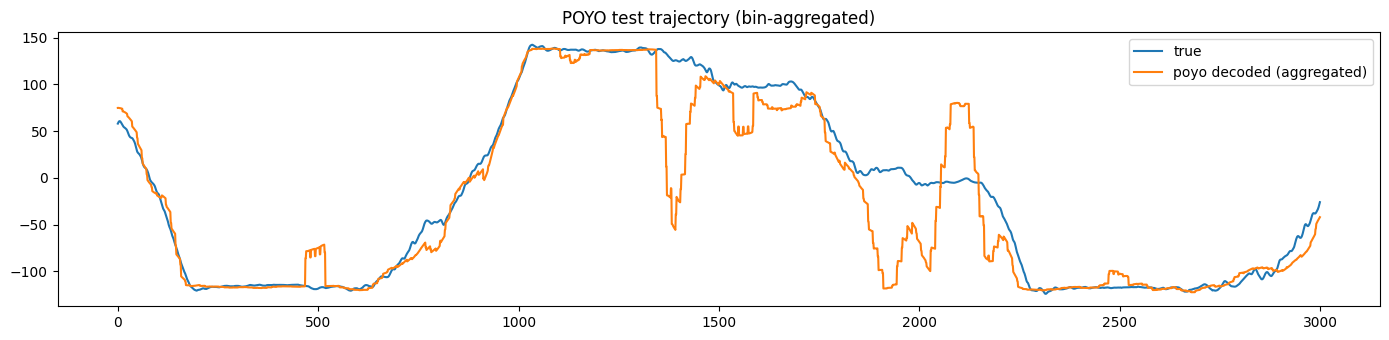

In [8]:

poyo.eval()
decode_session = sessions[0]
T = len(session_arrays[decode_session]["pos"])
test_bin_mask = session_arrays[decode_session]["split_masks"]["test"]

poyo_sum = np.zeros(T, dtype=np.float64)
poyo_count = np.zeros(T, dtype=np.int64)

with torch.no_grad():
    for batch in test_loader:
        batch = move_to_device(batch, device)
        starts = batch["window_start_bin"].cpu().numpy()
        pred = poyo(**batch["model_inputs"]).cpu().numpy()
        mask = batch["model_inputs"]["output_mask"].cpu().numpy()

        for b in range(pred.shape[0]):
            valid = mask[b]
            if not np.any(valid):
                continue
            local_bins = np.flatnonzero(valid)
            global_bins = starts[b] + local_bins
            poyo_sum[global_bins] += pred[b, local_bins, 0]
            poyo_count[global_bins] += 1

poyo_pred_full = np.zeros(T, dtype=np.float32)
has_pred = poyo_count > 0
poyo_pred_full[has_pred] = (poyo_sum[has_pred] / poyo_count[has_pred]).astype(np.float32)

poyo_eval_mask = test_bin_mask & has_pred
if not np.any(poyo_eval_mask):
    raise RuntimeError("No POYO test bins available after overlap aggregation.")

poyo_true_test = position_stream[poyo_eval_mask]
poyo_pred_test = poyo_pred_full[poyo_eval_mask]
poyo_r2 = r2_score(poyo_true_test, poyo_pred_test)
print(f"POYO aggregated test bins: {int(poyo_eval_mask.sum())}, R2={poyo_r2:.4f}")

nshow = min(3000, len(poyo_true_test))
plt.figure(figsize=(14, 3.5))
plt.plot(poyo_true_test[:nshow], label="true")
plt.plot(poyo_pred_test[:nshow], label="poyo decoded (aggregated)")
plt.title("POYO test trajectory (bin-aggregated)")
plt.legend()
plt.tight_layout()
plt.show()


COMETS test bins: 7677, R2=0.4167
Shared test bins=7658: POYO R2=0.6422, COMETS R2=0.4172


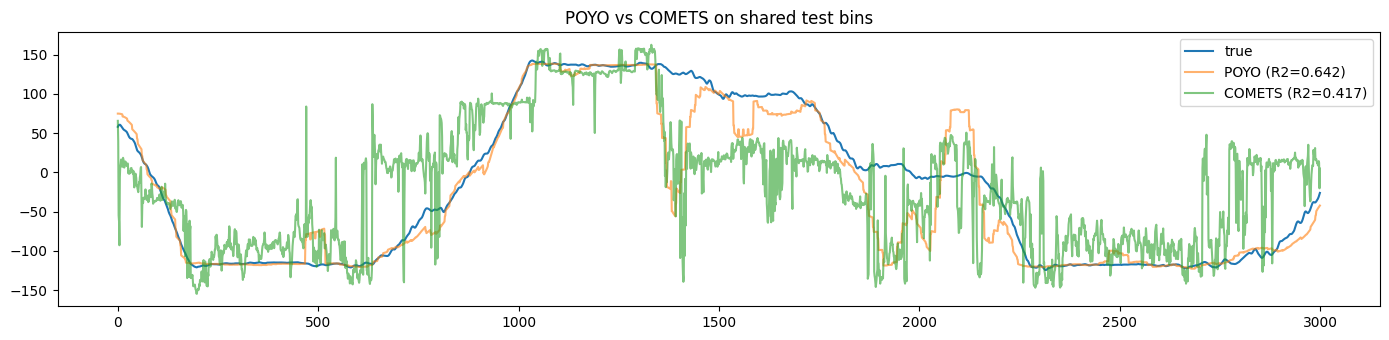

In [9]:

if not np.any(comets_train_mask):
    raise RuntimeError("No train bins available for COMETS ridge decode.")

ridge = Ridge(alpha=1.0)
ridge.fit(ZA_comets[comets_train_mask], position_stream[comets_train_mask])
comets_pred_full = ridge.predict(ZA_comets)

comets_true_test = position_stream[comets_test_mask]
comets_pred_test = comets_pred_full[comets_test_mask]
comets_r2 = r2_score(comets_true_test, comets_pred_test)
print(f"COMETS test bins: {int(comets_test_mask.sum())}, R2={comets_r2:.4f}")

# Compare on bins where both methods have predictions.
comparison_mask = comets_test_mask & (poyo_count > 0)
if not np.any(comparison_mask):
    raise RuntimeError("No overlapping test bins between POYO and COMETS predictions.")

common_true = position_stream[comparison_mask]
common_poyo = poyo_pred_full[comparison_mask]
common_comets = comets_pred_full[comparison_mask]
common_poyo_r2 = r2_score(common_true, common_poyo)
common_comets_r2 = r2_score(common_true, common_comets)
print(f"Shared test bins={int(comparison_mask.sum())}: POYO R2={common_poyo_r2:.4f}, COMETS R2={common_comets_r2:.4f}")

n_plot = min(3000, len(common_true))
plt.figure(figsize=(14, 3.5))
plt.plot(common_true[:n_plot], label="true", linewidth=1.5)
plt.plot(common_poyo[:n_plot], label=f"POYO (R2={common_poyo_r2:.3f})", alpha=0.6)
plt.plot(common_comets[:n_plot], label=f"COMETS (R2={common_comets_r2:.3f})", alpha=0.6)
plt.title("POYO vs COMETS on shared test bins")
plt.legend()
plt.tight_layout()
plt.show()


In [10]:
comets_window_radius = 4
comets_window_size = 2 * comets_window_radius + 1

def build_center_window_features(embedding, split_mask, radius):
    offsets = np.arange(-radius, radius + 1, dtype=np.int64)
    candidate_idx = np.flatnonzero(split_mask)
    candidate_idx = candidate_idx[(candidate_idx >= radius) & (candidate_idx < len(split_mask) - radius)]

    valid_idx = []
    for idx in candidate_idx:
        if split_mask[idx - radius : idx + radius + 1].all():
            valid_idx.append(int(idx))

    if not valid_idx:
        return np.empty((0, embedding.shape[1] * len(offsets)), dtype=np.float32), np.empty((0,), dtype=np.int64)

    valid_idx = np.asarray(valid_idx, dtype=np.int64)
    windowed = [embedding[valid_idx + offset] for offset in offsets]
    features = np.concatenate(windowed, axis=1).astype(np.float32)
    return features, valid_idx

X_train_window, train_window_idx = build_center_window_features(ZA_comets, comets_train_mask, comets_window_radius)
X_test_window, test_window_idx = build_center_window_features(ZA_comets, comets_test_mask, comets_window_radius)

if len(train_window_idx) == 0 or len(test_window_idx) == 0:
    raise RuntimeError("No valid centered-window bins available for COMETS window ridge decode.")

window_ridge = Ridge(alpha=1.0)
window_ridge.fit(X_train_window, position_stream[train_window_idx])

comets_window_pred_full = np.full(T, np.nan, dtype=np.float32)
comets_window_pred_full[test_window_idx] = window_ridge.predict(X_test_window).astype(np.float32)

comets_window_eval_mask = np.zeros(T, dtype=bool)
comets_window_eval_mask[test_window_idx] = True

comets_window_true_test = position_stream[comets_window_eval_mask]
comets_window_pred_test = comets_window_pred_full[comets_window_eval_mask]
comets_window_r2 = r2_score(comets_window_true_test, comets_window_pred_test)
print(
    f"COMETS centered-window ridge bins: {int(comets_window_eval_mask.sum())}, "
    f"window={comets_window_size}, R2={comets_window_r2:.4f}"
)


COMETS centered-window ridge bins: 7669, window=9, R2=0.4457


Shared centered-window test bins=7658: POYO R2=0.6422, COMETS window_ridge R2=0.4455


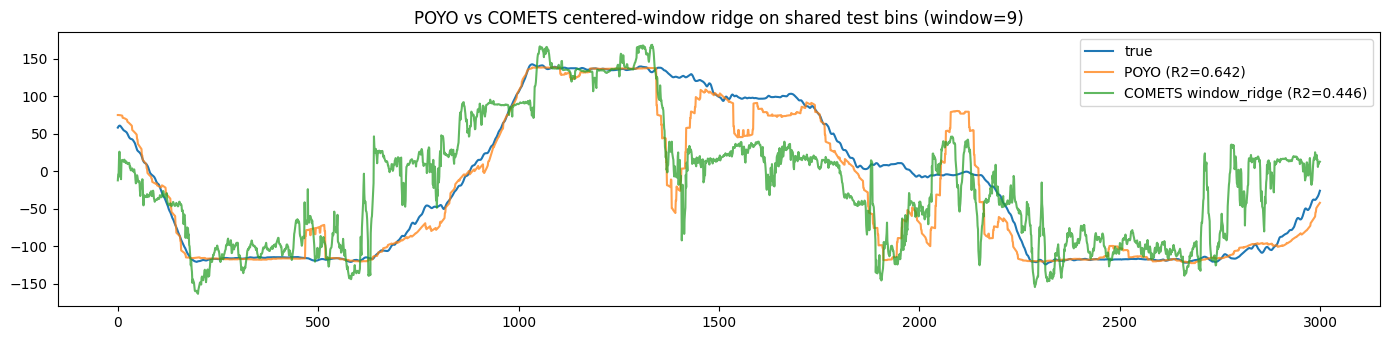

In [11]:
# Compare POYO against the centered-window COMETS ridge on shared test bins only.
comparison_window_mask = comets_window_eval_mask & (poyo_count > 0)
if not np.any(comparison_window_mask):
    raise RuntimeError("No overlapping test bins between POYO and COMETS centered-window ridge predictions.")

common_true_window = position_stream[comparison_window_mask]
common_poyo_window = poyo_pred_full[comparison_window_mask]
common_comets_window = comets_window_pred_full[comparison_window_mask]

common_poyo_window_r2 = r2_score(common_true_window, common_poyo_window)
common_comets_window_r2 = r2_score(common_true_window, common_comets_window)
print(
    f"Shared centered-window test bins={int(comparison_window_mask.sum())}: "
    f"POYO R2={common_poyo_window_r2:.4f}, COMETS window_ridge R2={common_comets_window_r2:.4f}"
)

n_plot = min(3000, len(common_true_window))
plt.figure(figsize=(14, 3.5))
plt.plot(common_true_window[:n_plot], label="true", linewidth=1.5)
plt.plot(common_poyo_window[:n_plot], label=f"POYO (R2={common_poyo_window_r2:.3f})", alpha=0.75)
plt.plot(
    common_comets_window[:n_plot],
    label=f"COMETS window_ridge (R2={common_comets_window_r2:.3f})",
    alpha=0.75,
)
plt.title(f"POYO vs COMETS centered-window ridge on shared test bins (window={comets_window_size})")
plt.legend()
plt.tight_layout()
plt.show()
